<a href="https://colab.research.google.com/github/NietoEmmanuel/SIMULACION-II/blob/main/Actividad4_BlackScholes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Ecuación de Black-Scholes: solución analítica con sympy**


La ecuación de Black-Scholes con dividendos continuos es

$$\frac{\partial V}{\partial t}+\frac{\sigma^2S^2}{2}\frac{\partial^2V}{\partial S^2}+(r-q)S\frac{\partial V}{\partial S}-rV=0.$$

La condición terminal de una opción de compra es $V(S,T)=\max(S-E,0)$.



**Los divideremos en 2 partes:**


1.   Solución directa mediante la fórmula de Black-Scholes
2.   Desarrollo analítico de la ecuación de Black-Scholes



# Solució Direct con la fórmula de Black-Scholes

In [1]:
import sympy as sy
from sympy.plotting import plot3d
sy.init_printing()

# 1. Ecuación de Black-Scholes
S = sy.symbols('S', positive=True)
t = sy.symbols('t', real=True)
V = sy.Function('V')(S, t)

sigma, r, q = sy.Rational(29,100), sy.Rational(4,100), 0
E, T = 60, sy.Rational(3,10)

ecuacion = sy.diff(V,t) + sigma**2*S**2/2*sy.diff(V,S,2) + (r-q)*S*sy.diff(V,S) - r*V
display(sy.Eq(ecuacion, 0))

# 2. Condición terminal
condicion = sy.Piecewise((S-E, S>=E), (0, True))
display(sy.Eq(V.subs(t,T), condicion))

        2                                                      
     2 ∂                                                       
841⋅S ⋅───(V(S, t))     ∂                                      
         2            S⋅──(V(S, t))                            
       ∂S               ∂S            V(S, t)   ∂              
─────────────────── + ───────────── - ─────── + ──(V(S, t)) = 0
       20000               25           25      ∂t             

             ⎧S - 60  for S ≥ 60
V(S, 3/10) = ⎨                  
             ⎩  0     otherwise 

### Condición terminal de la opción CALL


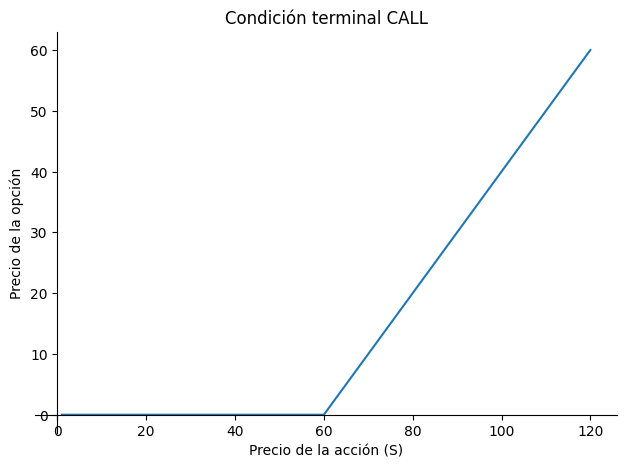

In [2]:
# 3. Gráfica de la condición terminal
sy.plot(condicion, (S, 1, 120), title='Condición terminal CALL',
        xlabel='Precio de la acción (S)', ylabel='Precio de la opción')

### Solución de Black-Scholes


In [3]:
# 4. Fórmula de Black-Scholes
d1 = ((r-q+sigma**2/2)*(T-t) + sy.log(S/E)) / (sigma*sy.sqrt(T-t))
d2 = d1 - sigma*sy.sqrt(T-t)
N = lambda d: (1 + sy.erf(d/sy.sqrt(2)))/2
solucion = S*sy.exp(-q*(T-t))*N(d1) - E*sy.exp(-r*(T-t))*N(d2)

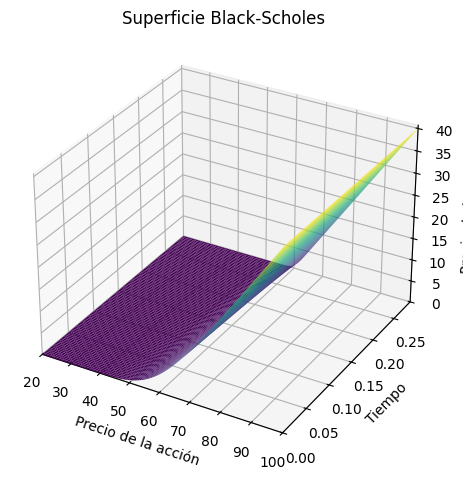

In [4]:
# 5. Gráfica de la solución
plot3d(solucion, (S, 20, 100), (t, 0, sy.Rational(29,100)), title='Superficie Black-Scholes',
       xlabel='Precio de la acción', ylabel='Tiempo', zlabel='Precio de la opción')

In [5]:
# 6. Precio actual de IBM
print("d1 =", sy.N(d1.subs({S:sy.Rational(117,2), t:0})))
print("d2 =", sy.N(d2.subs({S:sy.Rational(117,2), t:0})))
print("Precio de la opción:", sy.N(solucion.subs({S:sy.Rational(117,2), t:0}), 6))
precio_referencia = solucion.subs({S:sy.Rational(117,2), t:0})

d1 = -0.00442464122517588
d2 = -0.163264182901674
Precio de la opción: 3.34886


---
### Desarrollo analítico


In [9]:
from sympy.plotting import plot

sy.init_printing(use_latex='mathjax')

# S, E, sigma y T son positivos; q puede ser igual a cero.
S, E, sigma, T = sy.symbols('S E sigma T', positive=True)
r = sy.symbols('r', positive=True)
q = sy.symbols('q', nonnegative=True)
t, x, s, y, z = sy.symbols('t x s y z', real=True)
tau = sy.symbols('tau', positive=True)
alpha, beta, k = sy.symbols('alpha beta k', real=True)
V, W, Z, u = map(sy.Function, ['V', 'W', 'Z', 'u'])


datos = {S: sy.Rational(117, 2), E: sy.Integer(60),
         sigma: sy.Rational(29, 100), r: sy.Rational(4, 100),
         q: sy.Integer(0), T: sy.Rational(3, 10), t: sy.Integer(0)}

A = sigma**2 / 2
B = r - q - A
pago = sy.Max(S-E, 0)


original = sy.diff(V(S,t), t) + A*S**2*sy.diff(V(S,t), S, 2) + (r-q)*S*sy.diff(V(S,t), S) - r*V(S,t)
display(sy.Eq(original, 0), sy.Eq(V(S,T), pago))

       2                                                                 
 2  2 ∂                                                                  
S ⋅σ ⋅───(V(S, t))                                                       
        2                                                                
      ∂S                        ∂                         ∂              
────────────────── + S⋅(-q + r)⋅──(V(S, t)) - r⋅V(S, t) + ──(V(S, t)) = 0
        2                       ∂S                        ∂t             

V(S, T) = Max(0, -E + S)

## 1. Transformación del tiempo
Tomamos $\tau=T-t$, por lo que $t=T-\tau$ y $d\tau/dt=-1$. Definimos $W(S,\tau)=V(S,T-\tau)$.

Por la regla de la cadena, $V_t=-W_\tau$. Al sustituir en la ecuación original se obtiene una ecuación que evoluciona desde $\tau=0$, es decir, desde el vencimiento.

In [10]:
# Calculamos el signo que introduce el cambio de tiempo.
display(sy.Eq(sy.Derivative(sy.Function('tau')(t), t), sy.diff(T-t, t)))

w = W(S,tau)
# Sustitución simultánea de las derivadas y de la función original.
paso1 = original.xreplace({sy.diff(V(S,t), t): -sy.diff(w,tau),
                           sy.diff(V(S,t), S, 2): sy.diff(w,S,2),
                           sy.diff(V(S,t), S): sy.diff(w,S), V(S,t): w})

W_tau = sy.solve(paso1, sy.diff(w,tau))[0]
display(sy.Eq(sy.diff(w,tau), W_tau), sy.Eq(W(S,0), pago))

d            
──(τ(t)) = -1
dt           

                     2                                                          
               2  2 ∂                                                           
              S ⋅σ ⋅───(W(S, τ))                                                
                      2                                                         
∂                   ∂S                 ∂                 ∂                      
──(W(S, τ)) = ────────────────── - S⋅q⋅──(W(S, τ)) + S⋅r⋅──(W(S, τ)) - r⋅W(S, τ)
∂τ                    2                ∂S                ∂S                     

W(S, 0) = Max(0, -E + S)

## 2. Transformación logarítmica
Hacemos $S=e^x$, de manera que $x=\ln S$, y definimos

$$Z(x,\tau)=W(e^x,\tau),\qquad W(S,\tau)=Z(\ln S,\tau).$$

La ventaja de este cambio es que $x$ puede tomar cualquier valor real y los coeficientes que dependen de $S$ se convierten en constantes. Calculamos las primeras dos derivadas respecto a $S$.

In [11]:

w_log = Z(sy.log(S),tau)
WS = sy.simplify(sy.diff(w_log,S).subs(S,sy.exp(x)).doit())
WSS = sy.simplify(sy.diff(w_log,S,2).subs(S,sy.exp(x)).doit())
display(sy.Eq(sy.Symbol('W_S'), WS), sy.Eq(sy.Symbol('W_SS'), WSS))

# Reemplazamos S por exp(x) en el lado derecho de la ecuación.
paso2 = sy.simplify(A*sy.exp(2*x)*WSS + (r-q)*sy.exp(x)*WS - r*Z(x,tau))
Z_rhs = A*sy.diff(Z(x,tau),x,2) + B*sy.diff(Z(x,tau),x) - r*Z(x,tau)
assert sy.simplify(paso2-Z_rhs) == 0
display(sy.Eq(sy.diff(Z(x,tau),tau), Z_rhs),
        sy.Eq(Z(x,0), pago.subs(S,sy.exp(x))))

       -x ∂          
W_S = ℯ  ⋅──(Z(x, τ))
          ∂x         

       ⎛                 2          ⎞      
       ⎜  ∂             ∂           ⎟  -2⋅x
W_SS = ⎜- ──(Z(x, τ)) + ───(Z(x, τ))⎟⋅ℯ    
       ⎜  ∂x              2         ⎟      
       ⎝                ∂x          ⎠      

                               2                                      
                            2 ∂                                       
                           σ ⋅───(Z(x, τ))                            
                                2            ⎛          2⎞            
∂                             ∂x             ⎜         σ ⎟ ∂          
──(Z(x, τ)) = -r⋅Z(x, τ) + ─────────────── + ⎜-q + r - ──⎟⋅──(Z(x, τ))
∂τ                                2          ⎝         2 ⎠ ∂x         

Z(x, 0) = Max(0, -E + exp(x))

## 3. Transformación a la ecuación del calor
Para eliminar los términos de orden inferior $Z_x$ y $Z$, aplicamos

$$u(x,\tau)=e^{\alpha x+\beta\tau}Z(x,\tau),\qquad Z(x,\tau)=e^{-\alpha x-\beta\tau}u(x,\tau).$$

Usamos $A=\sigma^2/2$ y $B=r-q-\sigma^2/2$, de modo que la ecuación del paso anterior es $Z_\tau-AZ_{xx}-BZ_x+rZ=0$.

In [12]:
U = u(x,tau)
Z_exp = sy.exp(-alpha*x-beta*tau)*U

# Derivadas de la transformación exponencial.
Z_tau = sy.diff(Z_exp,tau)
Z_x = sy.diff(Z_exp,x)
Z_xx = sy.diff(Z_exp,x,2)
display(sy.Eq(sy.Symbol('Z_tau'), Z_tau), sy.Eq(sy.Symbol('Z_x'), Z_x),
        sy.Eq(sy.Symbol('Z_xx'), Z_xx))

# Se cancela el factor exponencial común y se agrupan las derivadas.
terminos = [sy.diff(U,tau), sy.diff(U,x,2), sy.diff(U,x), U]
raw = Z_tau - A*Z_xx - B*Z_x + r*Z_exp
paso3 = sy.collect(sy.expand(sy.simplify(raw/sy.exp(-alpha*x-beta*tau))), terminos)
display(sy.Eq(paso3,0))

                    -α⋅x - β⋅τ    -α⋅x - β⋅τ ∂          
Zₜₐᵤ = - β⋅u(x, τ)⋅ℯ           + ℯ          ⋅──(u(x, τ))
                                             ∂τ         

                  -α⋅x - β⋅τ    -α⋅x - β⋅τ ∂          
Zₓ = - α⋅u(x, τ)⋅ℯ           + ℯ          ⋅──(u(x, τ))
                                           ∂x         

      ⎛                                2          ⎞            
      ⎜ 2               ∂             ∂           ⎟  -α⋅x - β⋅τ
Zₓₓ = ⎜α ⋅u(x, τ) - 2⋅α⋅──(u(x, τ)) + ───(u(x, τ))⎟⋅ℯ          
      ⎜                 ∂x              2         ⎟            
      ⎝                               ∂x          ⎠            

      2                                                                        ↪
   2 ∂                                                                         ↪
  σ ⋅───(u(x, τ))                                                              ↪
       2            ⎛                2⎞               ⎛   2  2                 ↪
     ∂x             ⎜   2           σ ⎟ ∂             ⎜  α ⋅σ                α ↪
- ─────────────── + ⎜α⋅σ  + q - r + ──⎟⋅──(u(x, τ)) + ⎜- ───── - α⋅q + α⋅r - ─ ↪
         2          ⎝               2 ⎠ ∂x            ⎝    2                   ↪

↪                                       
↪                                       
↪                                       
↪   2        ⎞                          
↪ ⋅σ         ⎟           ∂              
↪ ─── - β + r⎟⋅u(x, τ) + ──(u(x, τ)) = 0
↪ 2          ⎠           ∂τ             

In [13]:
# Igualamos a cero los coeficientes de u_x y u.
coef_ux = sy.factor(paso3.coeff(sy.diff(U,x)))
coef_u = sy.factor(paso3.coeff(U))
display(sy.Eq(coef_ux,0), sy.Eq(coef_u,0))

alpha_sol = sy.factor(sy.solve(coef_ux,alpha)[0])
beta_sol = sy.factor(sy.solve(coef_u.subs(alpha,alpha_sol),beta)[0])
display(sy.Eq(alpha,alpha_sol), sy.Eq(beta,beta_sol))

# Comprobamos que solo queden las derivadas de la ecuación del calor.
calor = sy.simplify(paso3.subs({alpha:alpha_sol,beta:beta_sol}))
assert sy.simplify(calor-(sy.diff(U,tau)-A*sy.diff(U,x,2))) == 0
u0 = sy.exp(alpha_sol*x)*pago.subs(S,sy.exp(x))
display(sy.Eq(sy.diff(U,tau), A*sy.diff(U,x,2)), sy.Eq(u(x,0),u0))

# Constantes para los datos de IBM.
for nombre, valor in [('alpha',alpha_sol),('beta',beta_sol),('a^2',A)]:
    print(nombre, '=', valor.subs(datos).evalf(9))

     2                2    
2⋅α⋅σ  + 2⋅q - 2⋅r + σ     
─────────────────────── = 0
           2               

 ⎛ 2  2                      2            ⎞     
-⎝α ⋅σ  + 2⋅α⋅q - 2⋅α⋅r + α⋅σ  + 2⋅β - 2⋅r⎠     
──────────────────────────────────────────── = 0
                     2                          

     ⎛             2⎞ 
    -⎝2⋅q - 2⋅r + σ ⎠ 
α = ──────────────────
              2       
           2⋅σ        

       2                2      2        2    4
    4⋅q  - 8⋅q⋅r + 4⋅q⋅σ  + 4⋅r  + 4⋅r⋅σ  + σ 
β = ──────────────────────────────────────────
                          2                   
                       8⋅σ                    

                  2          
               2 ∂           
              σ ⋅───(u(x, τ))
                   2         
∂                ∂x          
──(u(x, τ)) = ───────────────
∂τ                   2       

              ⎛             2⎞                     
           -x⋅⎝2⋅q - 2⋅r + σ ⎠                     
           ────────────────────                    
                      2                            
                   2⋅σ                             
u(x, 0) = ℯ                    ⋅Max(0, -E + exp(x))

alpha = -0.0243757432
beta = 0.0400249851
a^2 = 0.0420500000


Así se obtiene $u_\tau=a^2u_{xx}$, donde $a^2=\sigma^2/2$. La condición inicial es $u(x,0)=e^{\alpha x}\max(e^x-E,0)$.

## 4. Aplicación de la fórmula de Green
La solución de la ecuación del calor se expresa como

$$u(x,\tau)=\frac{1}{\sqrt{2\pi\sigma^2\tau}}\int_{-\infty}^{\infty}e^{-\frac{(x-s)^2}{2\sigma^2\tau}}u(s,0)\,ds.$$

Al regresar a $V$ y sustituir $x=\ln S$, obtenemos la ecuación (3) de la actividad. Como $e^s-E>0$ solamente cuando $s>\ln E$, podemos cambiar el límite inferior a $\ln E$ y retirar el máximo de la integral.

In [14]:

G = sy.exp(-(x-s)**2/(2*sigma**2*tau))/sy.sqrt(2*sy.pi*sigma**2*tau)
u_green = sy.Integral(G*sy.exp(alpha*s)*sy.Max(sy.exp(s)-E,0),(s,-sy.oo,sy.oo))
display(sy.Eq(U,u_green))

# Recuperación de la variable original y eliminación del tramo de pago cero.
V_integral = sy.exp(-beta*tau-alpha*sy.log(S))*sy.Integral(
    G.subs(x,sy.log(S))*sy.exp(alpha*s)*(sy.exp(s)-E),(s,sy.log(E),sy.oo))
display(sy.Eq(V(S,T-tau),V_integral))

          ∞                                             
          ⌠                                             
          ⎮                    2                        
          ⎮           -(-s + x)                         
          ⎮           ───────────                       
          ⎮                2                            
          ⎮      α⋅s    2⋅σ ⋅τ                          
          ⎮  √2⋅ℯ   ⋅ℯ           ⋅Max(0, -E + exp(s))   
u(x, τ) = ⎮  ──────────────────────────────────────── ds
          ⎮                 2⋅√π⋅σ⋅√τ                   
          ⌡                                             
          -∞                                            

                                 ∞                                          
                                 ⌠                                          
                                 ⎮                                     2    
                                 ⎮                       -(-s + log(S))     
                                 ⎮                       ────────────────   
                                 ⎮                               2          
                                 ⎮       ⎛      s⎞  α⋅s       2⋅σ ⋅τ        
               -α⋅log(S) - β⋅τ   ⎮    √2⋅⎝-E + ℯ ⎠⋅ℯ   ⋅ℯ                   
V(S, T - τ) = ℯ               ⋅  ⎮    ─────────────────────────────────── ds
                                 ⎮                 2⋅√π⋅σ⋅√τ                
                                 ⌡                                          
                               log(E)                                       

### 4.1. Cambio de variable y separación de integrales
Con $y=s-\ln S$, el nuevo límite inferior es $\ln(E/S)$. La integral se separa en dos términos:

$$V(S,T-\tau)=e^{-\beta\tau}\left[S I(\alpha+1)-E I(\alpha)\right],$$

$$I(k)=\frac{1}{\sqrt{2\pi\sigma^2\tau}}\int_{\ln(E/S)}^{\infty}\exp\left(-\frac{y^2}{2\sigma^2\tau}+ky\right)dy.$$

Para calcular $I(k)$ completamos el cuadrado y hacemos un segundo cambio de variable, $z=(y-k\sigma^2\tau)/(\sigma\sqrt{\tau})$.

In [15]:
L = sy.log(E/S)
# Límite inferior después del primer cambio de variable.
display(sy.Eq(sy.Symbol('L'), L))
I_k = sy.Integral(sy.exp(-y**2/(2*sigma**2*tau)+k*y)/sy.sqrt(2*sy.pi*sigma**2*tau),
                  (y,L,sy.oo))
display(sy.Eq(sy.Function('I')(k),I_k))

# Completamos el cuadrado y comprobamos la identidad por expansión.
exponente = -y**2/(2*sigma**2*tau)+k*y
cuadrado = -(y-k*sigma**2*tau)**2/(2*sigma**2*tau)+k**2*sigma**2*tau/2
assert sy.expand(exponente-cuadrado) == 0
display(sy.Eq(exponente,cuadrado,evaluate=False))

# Sustitución inversa y = k*sigma**2*tau + sigma*sqrt(tau)*z.
y_z = k*sigma**2*tau+sigma*sy.sqrt(tau)*z
jac = sy.diff(y_z,z)
z_inf = sy.solve(y_z-L,z)[0]
display(sy.Eq(sy.Symbol('z_0'),z_inf),sy.Eq(sy.Symbol('dy_dz'),jac))

       ⎛E⎞
L = log⎜─⎟
       ⎝S⎠

         ∞                       
         ⌠                       
         ⎮                 2     
         ⎮                y      
         ⎮        k⋅y - ──────   
         ⎮                 2     
         ⎮              2⋅σ ⋅τ   
         ⎮    √2⋅ℯ               
I(k) =   ⎮    ──────────────── dy
         ⎮       2⋅√π⋅σ⋅√τ       
         ⌡                       
          ⎛E⎞                    
       log⎜─⎟                    
          ⎝S⎠                    

                                       2
         2      2  2     ⎛     2      ⎞ 
        y      k ⋅σ ⋅τ   ⎝- k⋅σ ⋅τ + y⎠ 
k⋅y - ────── = ─────── - ───────────────
         2        2             2       
      2⋅σ ⋅τ                 2⋅σ ⋅τ     

          2        ⎛E⎞
     - k⋅σ ⋅τ + log⎜─⎟
                   ⎝S⎠
z₀ = ─────────────────
           σ⋅√τ       

dy_dz = σ⋅√τ

### 4.2. Evaluación analítica con la función error


In [16]:
# Un límite real genérico facilita la integración simbólica.
h = sy.symbols('h', real=True)
normal = sy.exp(-z**2/2)/sy.sqrt(2*sy.pi)
cola = sy.integrate(normal,(z,h,sy.oo))
cola = sy.simplify(cola.rewrite(sy.erf))
display(sy.Eq(sy.Integral(normal,(z,h,sy.oo)),cola))

# Función de distribución acumulada normal estándar, obtenida de la cola.
def N(v):
    return sy.simplify(1-cola.subs(h,v))

display(sy.Eq(sy.Function('N')(h),N(h)))
I_res = sy.exp(k**2*sigma**2*tau/2)*cola.subs(h,z_inf)
display(sy.Eq(sy.Function('I')(k),I_res))

∞                            
⌠                            
⎮       2                    
⎮     -z                     
⎮     ────             ⎛√2⋅h⎞
⎮      2            erf⎜────⎟
⎮ √2⋅ℯ          1      ⎝ 2  ⎠
⎮ ──────── dz = ─ - ─────────
⎮   2⋅√π        2       2    
⌡                            
h                            

          ⎛√2⋅h⎞    
       erf⎜────⎟    
          ⎝ 2  ⎠   1
N(h) = ───────── + ─
           2       2

       ⎛       ⎛   ⎛     2        ⎛E⎞⎞⎞⎞         
       ⎜       ⎜√2⋅⎜- k⋅σ ⋅τ + log⎜─⎟⎟⎟⎟   2  2  
       ⎜       ⎜   ⎝              ⎝S⎠⎠⎟⎟  k ⋅σ ⋅τ
       ⎜    erf⎜──────────────────────⎟⎟  ───────
       ⎜1      ⎝        2⋅σ⋅√τ        ⎠⎟     2   
I(k) = ⎜─ - ───────────────────────────⎟⋅ℯ       
       ⎝2                2             ⎠         

### 4.3. Recuperación de la fórmula de Black-Scholes
Sustituimos $k=\alpha+1$ y $k=\alpha$ en las dos integrales. Al combinar los exponentes con $e^{-\beta\tau}$, los factores de descuento son $e^{-q\tau}$ y $e^{-r\tau}$, respectivamente.

In [17]:
# Obtenemos los exponentes que acompañan a las dos integrales.
factor1 = sy.simplify((-beta+k**2*sigma**2/2).subs({k:alpha+1}).subs({alpha:alpha_sol,beta:beta_sol}))
factor2 = sy.simplify((-beta+k**2*sigma**2/2).subs({k:alpha}).subs({alpha:alpha_sol,beta:beta_sol}))
display(sy.Eq(sy.Symbol('factor_1'),factor1),sy.Eq(sy.Symbol('factor_2'),factor2))
assert sy.simplify(factor1+q) == 0 and sy.simplify(factor2+r) == 0

# La cola normal en z_0 equivale a N(-z_0).
d1 = sy.simplify((-z_inf).subs(k,alpha+1).subs(alpha,alpha_sol))
d2 = sy.simplify((-z_inf).subs(k,alpha).subs(alpha,alpha_sol))
# Presentamos d1 y d2 con la notación de la actividad.
d1_forma = (sy.log(S/E)+(r-q+sigma**2/2)*tau)/(sigma*sy.sqrt(tau))
assert sy.simplify(d1-d1_forma) == 0
assert sy.simplify(d2-(d1_forma-sigma*sy.sqrt(tau))) == 0
d1 = d1_forma
d2 = d1-sigma*sy.sqrt(tau)
display(sy.Eq(sy.Symbol('d_1'),d1),sy.Eq(sy.Symbol('d_2'),d2))

# Resultado analítico, construido a partir de las integrales anteriores.
V_tau = S*sy.exp(factor1*tau)*N(d1)-E*sy.exp(factor2*tau)*N(d2)
V_t = V_tau.subs(tau,T-t)
display(sy.Eq(V(S,t),V_t))

factor₁ = -q

factor₂ = -r

       ⎛          2⎞         
       ⎜         σ ⎟      ⎛S⎞
     τ⋅⎜-q + r + ──⎟ + log⎜─⎟
       ⎝         2 ⎠      ⎝E⎠
d₁ = ────────────────────────
               σ⋅√τ          

               ⎛          2⎞         
               ⎜         σ ⎟      ⎛S⎞
             τ⋅⎜-q + r + ──⎟ + log⎜─⎟
               ⎝         2 ⎠      ⎝E⎠
d₂ = -σ⋅√τ + ────────────────────────
                       σ⋅√τ          

                                                                               ↪
                                                                               ↪
                                                                               ↪
              ⎛       ⎛   ⎛                             2                      ↪
              ⎜       ⎜√2⋅⎝2⋅q⋅(T - t) - 2⋅r⋅(T - t) + σ ⋅(T - t) + 2⋅log(E) - ↪
              ⎜    erf⎜─────────────────────────────────────────────────────── ↪
              ⎜       ⎜                                _______                 ↪
              ⎜1      ⎝                          4⋅σ⋅╲╱ T - t                  ↪
V(S, t) = - E⋅⎜─ - ─────────────────────────────────────────────────────────── ↪
              ⎝2                                     2                         ↪

↪                              ⎛   ⎛   ⎛                               ⎛ 2⎞⎞⎞  ↪
↪                              ⎜   ⎜   ⎜        ⎛              2⎞      ⎜S ⎟⎟⎟  ↪
↪                          

La expresión anterior es equivalente a la fórmula de la actividad:

$$\boxed{V(S,t)=Se^{-q(T-t)}N(d_1)-Ee^{-r(T-t)}N(d_2)}$$

con $N(d)=\frac{1}{2}\left[1+\operatorname{erf}\left(\frac{d}{\sqrt2}\right)\right]$.

## 5. Ejercicio: opción de compra de IBM
Ya que se pide el precio actual, usamos $t=0$ y $\tau=T-t=0.3$ años. Sustituimos los datos en la solución y evaluamos los resultados. Los cálculos conservan fracciones exactas hasta el final.

In [18]:
tau_0 = (T-t).subs(datos)
datos_tau = dict(datos)
datos_tau[tau] = tau_0

for nombre, expr in [('tau',tau),('d1',d1),('d2',d2),('N(d1)',N(d1)),('N(d2)',N(d2))]:
    print(f'{nombre:7} = {expr.subs(datos_tau).evalf(12)}')

# Valor de cada término descontado de la fórmula.
termino1 = (S*sy.exp(-q*tau)*N(d1)).subs(datos_tau)
termino2 = (E*sy.exp(-r*tau)*N(d2)).subs(datos_tau)
precio = V_t.subs(datos)
print('Primer término  =', termino1.evalf(12))
print('Segundo término =', termino2.evalf(12))
print('Precio de la opción =', precio.evalf(12))
display(sy.Eq(V(sy.Rational(117,2),0),precio.evalf(9)))

# Verificamos que el desarrollo analítico coincida con la fórmula inicial.
assert abs((precio-precio_referencia).evalf()) < sy.Rational(1,10**10)
print("La solución analítica coincide con el valor de referencia.")

tau     = 0.300000000000
d1      = -0.00442464122518
d2      = -0.163264182902
N(d1)   = 0.498234829299
N(d2)   = 0.435155216691
Primer término  = 29.1467375140
Segundo término = 25.7978736190
Precio de la opción = 3.34886389501


V(117/2, 0) = 3.3488639

La solución analítica coincide con el valor de referencia.


### <span style="color:#176c45">Resultado del ejercicio</span>

$$\boxed{V(58.5,0)\approx 3.348864\approx 3.35}$$

El precio teórico de la opción de compra es **3.35 unidades monetarias por acción** (dólares si los precios de IBM están expresados en dólares).

---


# Graficas

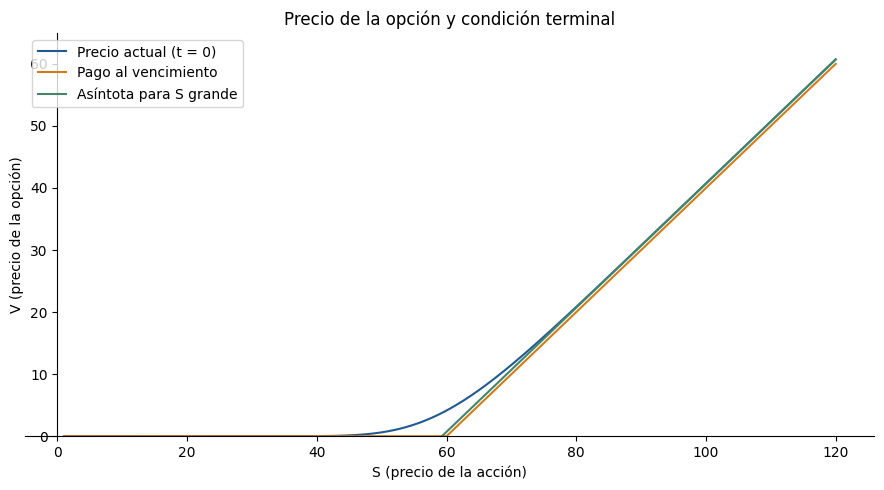

In [19]:
# Fijamos todos los parámetros excepto S y t.
parametros = {var:val for var,val in datos.items() if var not in (S,t)}
V_ibm = V_t.subs(parametros)
V_hoy = V_ibm.subs(t,0)
pago_ibm = pago.subs(parametros)
asintota = (S-E*sy.exp(-r*T)).subs(parametros)


p = plot(V_hoy,pago_ibm,asintota,(S,1,120),show=False,legend=True,
         title='Precio de la opción y condición terminal',
         xlabel='S (precio de la acción)',ylabel='V (precio de la opción)',
         ylim=(0,65),size=(9,5))
p[0].label = 'Precio actual (t = 0)'; p[0].line_color = '#215a91'
p[1].label = 'Pago al vencimiento'; p[1].line_color = '#d17c1b'
p[2].label = 'Asíntota para S grande'; p[2].line_color = '#43856a'
p.show()

La curva azul es suave antes del vencimiento, mientras que el pago terminal tiene un cambio de pendiente en $S=60$. Para precios altos ambas curvas crecen aproximadamente de forma lineal; la curva actual se acerca a su asíntota. La frontera inferior es $V(0,t)=0$, entendida como límite cuando $S\to0^+$; no se introduce $S=0$ dentro del logaritmo.

### 6.2. Evolución temporal de la opción para $S=58.5$
En esta última gráfica mantenemos fijo el precio de la acción para observar únicamente el efecto del paso del tiempo. Al acercarse al vencimiento, el valor se aproxima a cero, porque $58.5<60$.

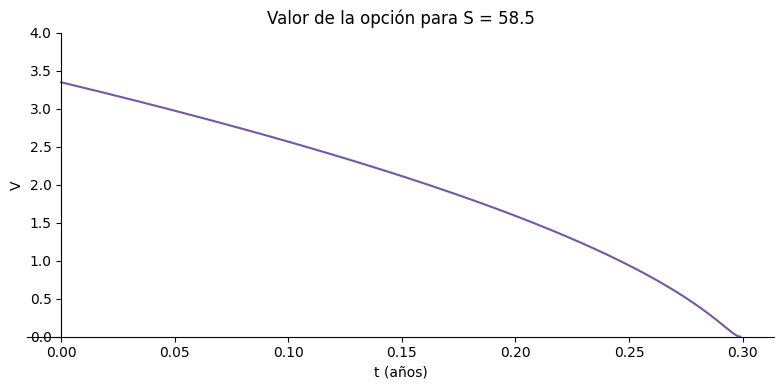

In [20]:
V_fijo = V_ibm.subs(S,datos[S])
p_t = plot(V_fijo,(t,0,sy.Rational(299,1000)),show=False,
           title='Valor de la opción para S = 58.5',
           xlabel='t (años)',ylabel='V',size=(8,4),ylim=(0,4))
p_t[0].line_color = '#7557a6'
p_t.show()